# What do the two six-gene panels measure?

## Summary

Both panels contain **GBP5**, which has a known role in host defense. The other genes cover several functions. They do not form one proven TB pathway.

- The published panel contains genes linked to immune responses, membrane repair, cell structure, mitochondrial removal and RNA/iron handling.
- The XGBoost panel contains genes linked to immune responses, blood-cell development and calcium signaling.
- In our saved adult data, GBP5 is higher in TB in all three datasets after adjustment for study and estimated RNA sources.

This notebook makes three figures from existing evidence. It does not train a model or repeat the genome-wide analysis.

See [gene_interactions_pathways.ipynb](gene_interactions_pathways.ipynb) for the full analysis and experimental context.

## 1. Keep three kinds of evidence separate

**GFS** means greedy forward selection. It builds a panel by adding one gene at a time using a defined score. **GLM** here is a logistic model that combines gene values into a TB probability. **XGBoost** combines decision trees. Each tree applies a sequence of rules to gene values.

**cfRNA** means cell-free RNA measured in plasma. **Expression** here means the measured abundance of RNA assigned to a gene.

A **panel** is the six genes supplied to a prediction model. A **pathway** is a set of connected biological processes. A **response signature** is a set of genes that change together under a condition.

| Evidence | What it tells us | What it does not show |
|---|---|---|
| Experimental function | What a protein can do in a studied cell or animal system | That this function causes its plasma RNA signal in TB |
| Curated membership | A database includes a gene in a pathway or response signature | That the pathway is active in our patients |
| Observed RNA association | RNA abundance differs with TB in our adult datasets | Protein activity, causation or pediatric transfer |

**Enrichment** tests whether a gene set appears more often than expected under a defined comparison. The membership map below is not an enrichment test.

### Assumptions

The literature includes human-cell and mouse experiments. These systems differ from plasma cfRNA. A gene can have more than one function. The short descriptions are examples, not complete inventories.

The original analysis used 130 training adults, 61 test adults and 60 external-validation adults. All figures here use saved, aggregate outputs.

In [1]:
import hashlib
import json
import os
from pathlib import Path

for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "1"

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Files_For_Manuscript").is_dir())
OUTPUT = ROOT / "Figure_Output/Gene_Interactions/focused"
RESOURCES = ROOT / "Files_For_Manuscript/gene_interactions_reference"
PAPER = ["GBP5", "BNIP3L", "KLF6", "DYSF", "LASP1", "PCBP1"]
XGBOOST = ["GBP5", "AHNAK", "JMJD1C", "MNDA", "LYZ", "SPI1"]
GENES = PAPER + XGBOOST[1:]
COLORS = {"Paper": "#386A87", "XGBoost": "#AC4B75", "Shared": "#495560"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 220})

def save_figure(figure, name):
    for extension in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"{name}.{extension}", bbox_inches="tight", facecolor="white")

inputs = [RESOURCES / "gene_function_evidence.json",
          RESOURCES / "pathways_hallmark_2026.1.gmt",
          RESOURCES / "pathways_reactome_2026.1.gmt",
          OUTPUT / "pathway_gene_membership.csv",
          OUTPUT / "pathway_selected_gene_tb_associations.csv",
          OUTPUT / "six_gene_panel_genes.csv"]
input_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs}
evidence = pd.DataFrame(json.loads(inputs[0].read_text())["genes"]).set_index("gene")
membership = pd.read_csv(OUTPUT / "pathway_gene_membership.csv")
associations = pd.read_csv(OUTPUT / "pathway_selected_gene_tb_associations.csv")
assert len(GENES) == len(set(GENES)) == 11
assert set(PAPER) & set(XGBOOST) == {"GBP5"}
assert set(GENES) == set(evidence.index) == set(associations.gene)
assert len(associations) == 66
panel_definitions = pd.read_csv(OUTPUT / "six_gene_panel_genes.csv")
assert panel_definitions.loc[panel_definitions.panel.eq("Paper GFS genes")].sort_values("order").gene.tolist() == PAPER
assert panel_definitions.loc[panel_definitions.panel.eq("XGBoost CV genes")].sort_values("order").gene.tolist() == XGBOOST
assert not associations.duplicated(["gene", "split", "adjustment"]).any()
print("Checked: 2 panels, 11 unique genes, 66 saved association estimates.")

Checked: 2 panels, 11 unique genes, 66 saved association estimates.


## 2. See the functions of both panels

A **protein** is a molecule made from a gene's instructions. **Host defense** means protection against infection. **Interferons** are immune signals that change gene expression.

**Myeloid cells** include monocytes, macrophages and neutrophils. A **macrophage** is an immune cell that takes up material and responds to infection. **Mitochondria** supply much of a cell's energy. Developing red blood cells remove them during maturation.

The diagram shows each gene next to a function supported by prior experiments. GBP5 appears in both columns because both models use it. These are biological functions, not the model's prediction weights.

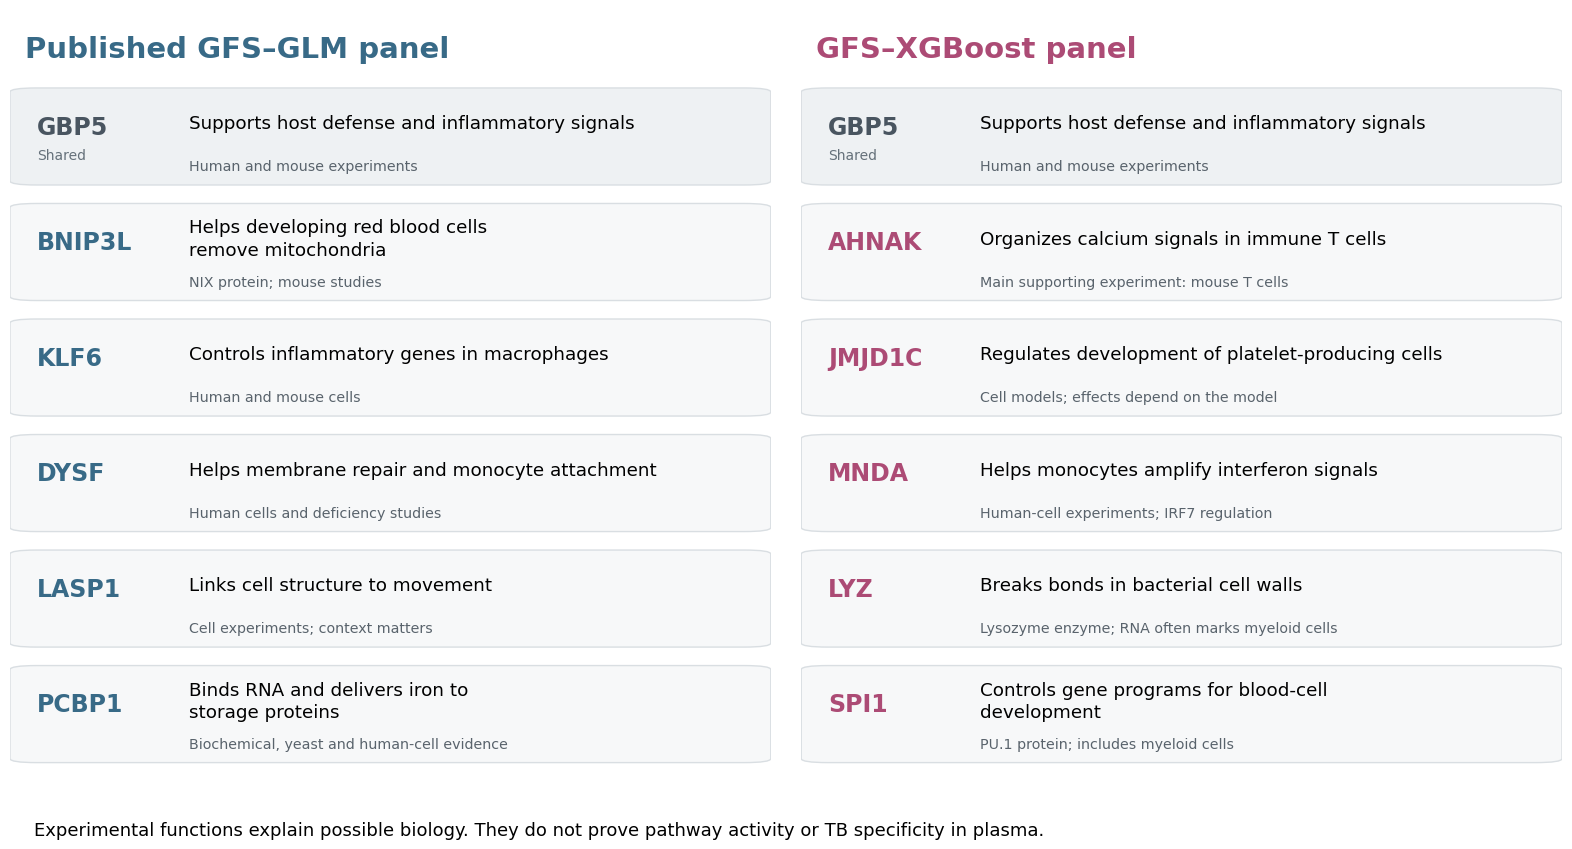

In [2]:
# Short summaries are linked to the full evidence records loaded above.
function_labels = {
    "GBP5": ("Supports host defense and inflammatory signals", "Human and mouse experiments"),
    "BNIP3L": ("Helps developing red blood cells remove mitochondria", "NIX protein; mouse studies"),
    "KLF6": ("Controls inflammatory genes in macrophages", "Human and mouse cells"),
    "DYSF": ("Helps membrane repair and monocyte attachment", "Human cells and deficiency studies"),
    "LASP1": ("Links cell structure to movement", "Cell experiments; context matters"),
    "PCBP1": ("Binds RNA and delivers iron to storage proteins", "Biochemical, yeast and human-cell evidence"),
    "AHNAK": ("Organizes calcium signals in immune T cells", "Main supporting experiment: mouse T cells"),
    "JMJD1C": ("Regulates development of platelet-producing cells", "Cell models; effects depend on the model"),
    "MNDA": ("Helps monocytes amplify interferon signals", "Human-cell experiments; IRF7 regulation"),
    "LYZ": ("Breaks bonds in bacterial cell walls", "Lysozyme enzyme; RNA often marks myeloid cells"),
    "SPI1": ("Controls gene programs for blood-cell development", "PU.1 protein; includes myeloid cells"),
}
figure, axes = plt.subplots(1, 2, figsize=(16, 8.6))
for axis, genes, title, color in zip(axes, [PAPER, XGBOOST],
        ["Published GFS–GLM panel", "GFS–XGBoost panel"], [COLORS["Paper"], COLORS["XGBoost"]]):
    axis.set(xlim=(0, 1), ylim=(0, 6.7))
    axis.axis("off")
    axis.text(0.02, 6.35, title, color=color, fontsize=21, weight="bold", va="center")
    for row, gene in enumerate(genes):
        y = 5.58 - row
        fill = "#EEF1F3" if gene == "GBP5" else "#F7F8F9"
        axis.add_patch(FancyBboxPatch((0.01, y - 0.39), 0.98, 0.82,
            boxstyle="round,pad=0.01,rounding_size=0.035", facecolor=fill, edgecolor="#D9DEE2"))
        axis.text(0.035, y + 0.10, gene, weight="bold", color=COLORS["Shared"] if gene == "GBP5" else color,
                  fontsize=17, va="center")
        axis.text(0.035, y - 0.18, "Shared" if gene == "GBP5" else "", fontsize=10, color="#65717A")
        function, context = function_labels[gene]
        axis.text(0.235, y + 0.13, function.replace("blood cells remove", "blood cells\nremove")
                  .replace("blood-cell development", "blood-cell\ndevelopment")
                  .replace("iron to storage", "iron to\nstorage"), fontsize=13.2, va="center", linespacing=1.35)
        axis.text(0.235, y - 0.24, context, fontsize=10.3, color="#59636C", va="center")
figure.text(0.035, 0.02, "Experimental functions explain possible biology. They do not prove pathway activity or TB specificity in plasma.", fontsize=13)
figure.subplots_adjust(left=0.02, right=0.99, bottom=0.08, top=0.98, wspace=0.04)
save_figure(figure, "two_panel_functions")
plt.show()
function_table = evidence.loc[GENES, ["function", "evidence_context", "limitation", "sources"]].copy()
function_table["panel"] = ["Shared" if g == "GBP5" else "Paper" if g in PAPER else "XGBoost" for g in GENES]
function_table["figure_function"] = [function_labels[g][0] for g in GENES]
function_table["source_urls"] = function_table.sources.map(lambda sources: "; ".join(s["url"] for s in sources))
function_table.drop(columns="sources").to_csv(OUTPUT / "two_panel_function_evidence.csv")

### How to read the diagram

The two panels share a host-response marker, GBP5. The XGBoost panel adds several genes associated with myeloid cells and blood-cell development. The published panel also contains immune genes, including KLF6 and DYSF. It also spans other cellular functions.

A mixture of functions can improve prediction. It does not mean the genes act together in one pathway. The classifier may combine RNA abundance from different sources.

**NIX** is the protein encoded by BNIP3L. **PU.1** is the protein encoded by SPI1. **IRF7** controls genes involved in interferon responses. **T cells** are immune cells that recognize specific targets. Platelet-producing cells are called **megakaryocytes**.

In [3]:
reference_lines = []
for gene in GENES:
    links = "; ".join(f"[{source['label']}]({source['url']})" for source in evidence.loc[gene, "sources"])
    reference_lines.append(f"- **{gene}:** {links}")
display(Markdown("### Sources for each gene\n\n" + "\n".join(reference_lines)))

### Sources for each gene

- **GBP5:** [Sweeney et al., 2016: multicohort human TB signature](https://pubmed.ncbi.nlm.nih.gov/26907218/); [Shenoy et al., 2012: experimental GBP5 function](https://pubmed.ncbi.nlm.nih.gov/22461501/)
- **BNIP3L:** [Schweers et al., 2007](https://pubmed.ncbi.nlm.nih.gov/18048346/)
- **KLF6:** [Macrophage polarization study](https://pmc.ncbi.nlm.nih.gov/articles/PMC4036156/); [Human macrophage study](https://pmc.ncbi.nlm.nih.gov/articles/PMC7774039/)
- **DYSF:** [Human monocyte adhesion](https://pmc.ncbi.nlm.nih.gov/articles/PMC3656271/); [Deficiency and phagocytosis](https://pmc.ncbi.nlm.nih.gov/articles/PMC2258254/)
- **LASP1:** [Focal adhesion and migration](https://pubmed.ncbi.nlm.nih.gov/15138294/); [Gene-disruption study](https://pubmed.ncbi.nlm.nih.gov/19531578/)
- **PCBP1:** [Iron delivery to ferritin](https://pubmed.ncbi.nlm.nih.gov/18511687/)
- **AHNAK:** [Matza et al., 2008: AHNAK1 and T-cell activation](https://pubmed.ncbi.nlm.nih.gov/18191595/)
- **JMJD1C:** [JMJD1C in megakaryopoiesis models (2022)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9688414/); [Staehle et al., 2020: adult mouse knockout](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0228362)
- **MNDA:** [Gu et al., 2022: MNDA–IRF7 mechanism](https://pubmed.ncbi.nlm.nih.gov/35013241/)
- **LYZ:** [Lyu et al., 2024: human TB single-cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC10953544/); [Reactome: LYZ–peptidoglycan reaction](https://reactome.org/content/detail/R-HSA-8862300)
- **SPI1:** [Chen et al., 1995: PU.1 expression in myeloid cells](https://pubmed.ncbi.nlm.nih.gov/7742552/); [Human MNDA promoter analysis (1997)](https://pubmed.ncbi.nlm.nih.gov/9136080/)

## 3. Check exact pathway membership

**MSigDB** is a database of named gene sets. **Reactome** sets describe curated biological pathways. **Hallmark** sets summarize expression patterns associated with biological responses.

We use the saved human release, **2026.1.Hs**. We show selected terms that describe the panel genes. This is a descriptive display chosen from prior functions. We did not select terms by a TB P value.

A colored dot means the gene is present in that exact set. A gray dot means it is absent from that set. A gray dot does not mean the gene lacks a related function. LASP1 is absent from both complete collections scanned here, despite its experimental functions.

**Heme** is the iron-containing part of hemoglobin. **Splicing** joins RNA segments after other segments are removed. **Granules** are storage compartments inside cells. Neutrophil degranulation means release of their contents. **IL2–STAT5** and **TNF–NF-κB** name immune signaling routes.

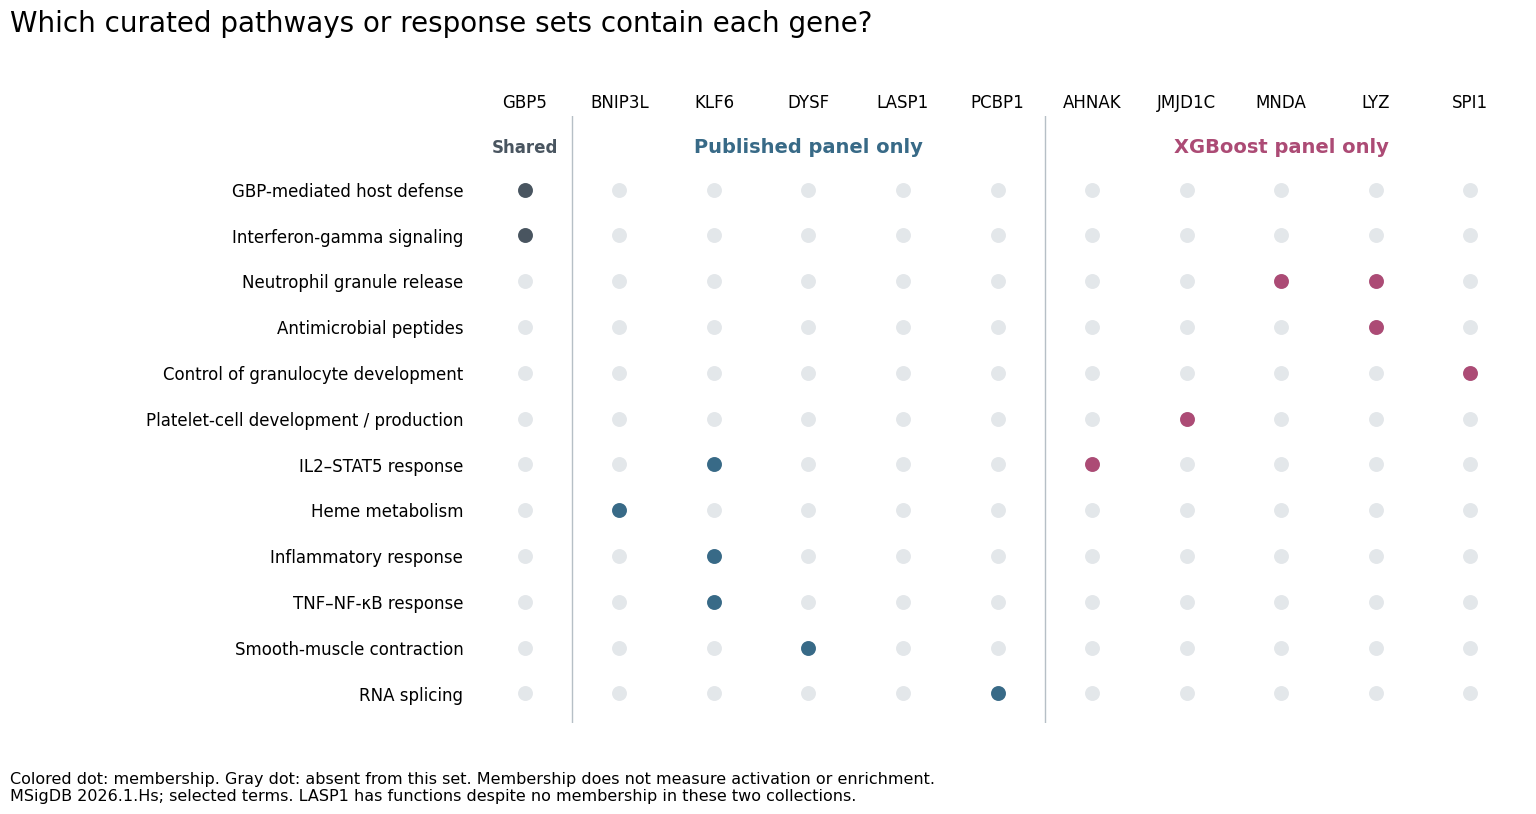

In [4]:
pathway_labels = {
    "REACTOME_GBP_MEDIATED_HOST_DEFENSE": "GBP-mediated host defense",
    "REACTOME_INTERFERON_GAMMA_SIGNALING": "Interferon-gamma signaling",
    "REACTOME_NEUTROPHIL_DEGRANULATION": "Neutrophil granule release",
    "REACTOME_ANTIMICROBIAL_PEPTIDES": "Antimicrobial peptides",
    "REACTOME_TRANSCRIPTIONAL_REGULATION_OF_GRANULOPOIESIS": "Control of granulocyte development",
    "REACTOME_FACTORS_INVOLVED_IN_MEGAKARYOCYTE_DEVELOPMENT_AND_PLATELET_PRODUCTION": "Platelet-cell development / production",
    "HALLMARK_IL2_STAT5_SIGNALING": "IL2–STAT5 response",
    "HALLMARK_HEME_METABOLISM": "Heme metabolism",
    "HALLMARK_INFLAMMATORY_RESPONSE": "Inflammatory response",
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB": "TNF–NF-κB response",
    "REACTOME_SMOOTH_MUSCLE_CONTRACTION": "Smooth-muscle contraction",
    "REACTOME_MRNA_SPLICING": "RNA splicing",
}
# Verify every selected membership directly against the pinned GMT collections.
gene_sets = {}
for filename in ["pathways_hallmark_2026.1.gmt", "pathways_reactome_2026.1.gmt"]:
    for line in (RESOURCES / filename).read_text().splitlines():
        name, source, *members = line.split("\t")
        gene_sets[name] = set(members)
matrix = pd.DataFrame({gene: [int(gene in gene_sets[term]) for term in pathway_labels]
                       for gene in GENES}, index=list(pathway_labels))
for term in matrix.index:
    saved = set(membership.loc[membership.pathway.eq(term), "gene"])
    assert saved == {g for g in GENES if matrix.loc[term, g]}
assert not any("LASP1" in genes for genes in gene_sets.values())
figure, axis = plt.subplots(figsize=(15.8, 8.2))
for row in range(len(matrix)):
    for column, gene in enumerate(GENES):
        axis.scatter(column, row, s=115, marker="o", color="#E3E7EA", linewidths=0)
        if matrix.iloc[row, column]:
            axis.scatter(column, row, s=115, marker="o", color=COLORS["Shared"] if gene == "GBP5"
                         else COLORS["Paper"] if gene in PAPER else COLORS["XGBoost"], linewidths=0)
axis.set(xticks=range(len(GENES)), xticklabels=GENES,
         yticks=range(len(matrix)), yticklabels=list(pathway_labels.values()),
         xlim=(-0.6, 10.6), ylim=(11.65, -1.6))
axis.tick_params(axis="both", length=0, labelsize=12)
axis.xaxis.tick_top()
for spine in axis.spines.values():
    spine.set_visible(False)
axis.axvline(0.5, color="#B6BFC6", linewidth=1)
axis.axvline(5.5, color="#B6BFC6", linewidth=1)
axis.text(0, -0.8, "Shared", ha="center", color=COLORS["Shared"], weight="bold", fontsize=12)
axis.text(3, -0.8, "Published panel only", ha="center", color=COLORS["Paper"], weight="bold", fontsize=14)
axis.text(8, -0.8, "XGBoost panel only", ha="center", color=COLORS["XGBoost"], weight="bold", fontsize=14)
figure.suptitle("Which curated pathways or response sets contain each gene?", x=0.03, ha="left", fontsize=20, y=0.99)
figure.text(0.03, 0.025, "Colored dot: membership. Gray dot: absent from this set. Membership does not measure activation or enrichment.\nMSigDB 2026.1.Hs; selected terms. LASP1 has functions despite no membership in these two collections.", fontsize=11.5)
figure.subplots_adjust(left=0.32, right=0.99, bottom=0.12, top=0.86)
save_figure(figure, "two_panel_pathway_membership")
plt.show()
matrix.rename_axis("pathway").to_csv(OUTPUT / "two_panel_pathway_membership.csv")

### What this adds to the story

GBP5 is listed in interferon and host-defense pathways. MNDA and LYZ share a neutrophil-granule annotation. SPI1 has a blood-cell development annotation. The other genes provide different or overlapping information.

The map does not justify a claim that the XGBoost panel is more biologically valid. Both panels have known functions. Nor can it explain why a trained model loses accuracy in a new study.

For the complete membership table, use `pathway_gene_membership.csv`. The full pathway notebook also tests broader expression programs after excluding panel genes. Exclusion prevents a score from containing the same gene that it is compared with.

## 4. Connect functions to what we measured

We now show the saved TB associations for all 11 genes. Each point is an estimated TB-versus-non-TB RNA difference. A positive value means higher RNA abundance in TB.

The analysis accounts for study and estimated RNA shares from different cell groups. RNA shares are not cell percentages. This adjustment cannot remove every biological or technical difference.

The unit is the gene's training standard deviation. A value of 1 means a difference equal to one training standard deviation. Bars show 95% confidence intervals from the fitted regression. The method adjusts uncertainty for unequal residual variation. These are the saved HC3 intervals.

Intervals are not adjusted for multiple testing. The saved table provides false-discovery-rate values across 66 gene, dataset and adjustment comparisons. No model is fitted in this notebook.

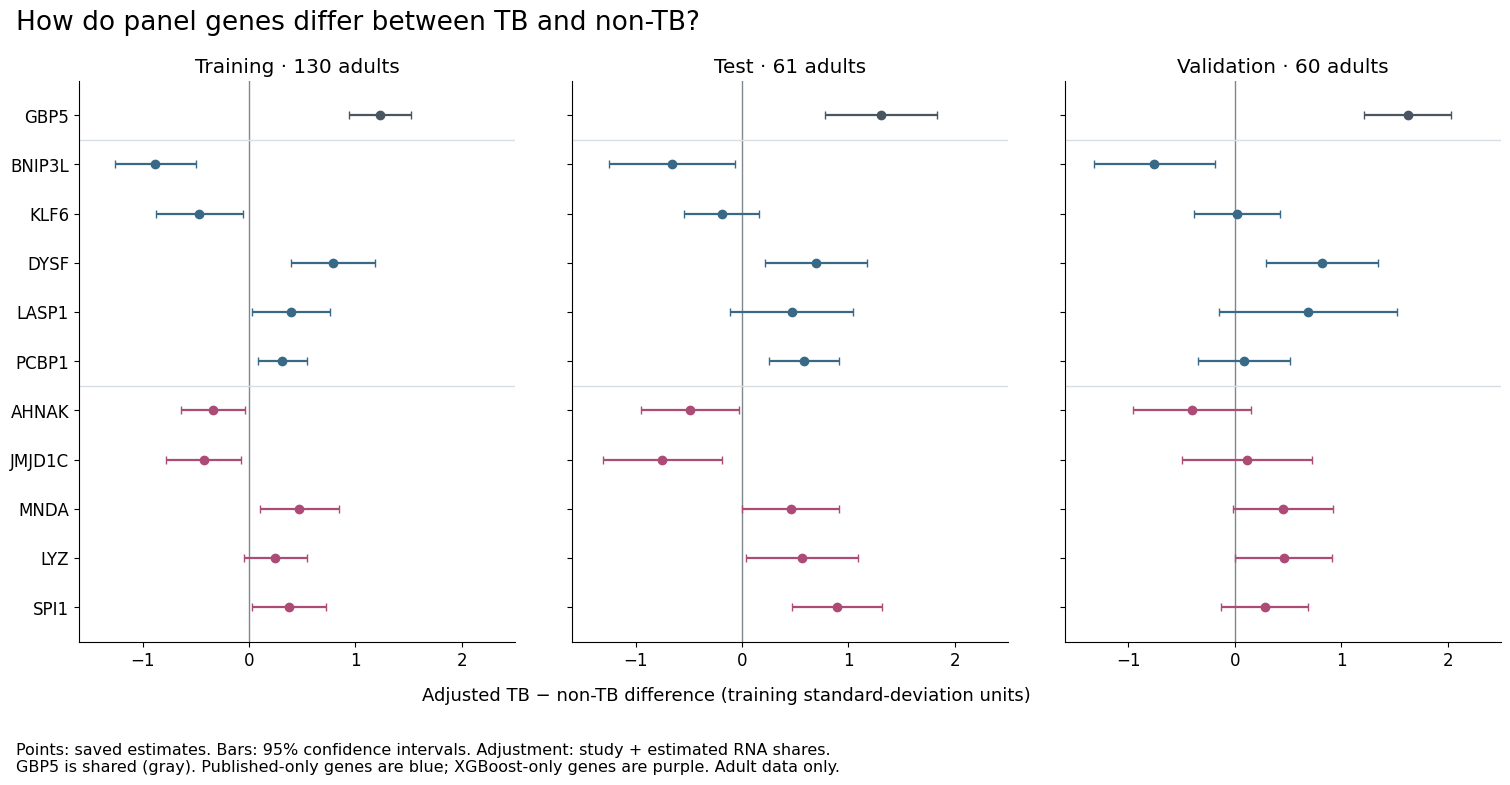

split  estimate  ci_lower  ci_upper  bh_fdr
train    1.2305    0.9413    1.5198  0.0000
 test    1.3099    0.7819    1.8378  0.0001
  val    1.6233    1.2146    2.0321  0.0000


In [5]:
adjusted = associations.loc[associations.adjustment.eq("Cohort + composition")].copy()
assert len(adjusted) == 33
assert np.isfinite(adjusted[["estimate", "ci_lower", "ci_upper"]]).all().all()
assert (adjusted.ci_lower <= adjusted.estimate).all() and (adjusted.estimate <= adjusted.ci_upper).all()
figure, axes = plt.subplots(1, 3, figsize=(15.8, 7.9), sharex=True, sharey=True)
for axis, split, title in zip(axes, ["train", "test", "val"], ["Training · 130 adults", "Test · 61 adults", "Validation · 60 adults"]):
    table = adjusted.loc[adjusted.split.eq(split)].set_index("gene").loc[GENES]
    axis.axvline(0, color="#7D878F", linewidth=1)
    for row, gene in enumerate(GENES):
        item = table.loc[gene]
        color = COLORS["Shared"] if gene == "GBP5" else COLORS["Paper"] if gene in PAPER else COLORS["XGBoost"]
        axis.errorbar(item.estimate, row, xerr=[[item.estimate-item.ci_lower], [item.ci_upper-item.estimate]],
                      fmt="o", color=color, capsize=3, markersize=6, linewidth=1.6)
    axis.set(title=title, yticks=range(len(GENES)), yticklabels=GENES, ylim=(10.7, -0.7), xlim=(-1.6, 2.5))
    axis.axhline(0.5, color="#D9DEE2", linewidth=1)
    axis.axhline(5.5, color="#D9DEE2", linewidth=1)
    axis.tick_params(labelsize=12)
    axis.set_xticks([-1, 0, 1, 2])
figure.suptitle("How do panel genes differ between TB and non-TB?", fontsize=19, x=0.05, ha="left", y=0.99)
figure.supxlabel("Adjusted TB − non-TB difference (training standard-deviation units)", y=0.11, fontsize=13)
figure.text(0.05, 0.025, "Points: saved estimates. Bars: 95% confidence intervals. Adjustment: study + estimated RNA shares.\nGBP5 is shared (gray). Published-only genes are blue; XGBoost-only genes are purple. Adult data only.", fontsize=11.5)
figure.subplots_adjust(left=0.09, right=0.99, bottom=0.19, top=0.90, wspace=0.13)
save_figure(figure, "two_panel_tb_associations")
plt.show()
print(adjusted.loc[adjusted.gene.eq("GBP5"), ["split", "estimate", "ci_lower", "ci_upper", "bh_fdr"]].round(4).to_string(index=False))

## 5. What can we conclude?

**GBP5 is the clearest shared result.** Its adjusted difference is positive in training, test and validation. The published panel also has consistent positive DYSF estimates and negative BNIP3L estimates. Several other estimates are smaller or less stable.

Known functions support interpretation, but they do not guarantee transfer to children or another adult study. Clinical groups, RNA sources and measurement procedures can differ. We need direct transfer experiments to test this.

Sequence models are a separate hypothesis. They may retain information about RNA fragments and transcript regions that gene totals discard. They must still prove a benefit against strong abundance models on the same people and reads.

The panel genes provide useful biological checks for future sequence attribution. We must not force a sequence model to recover them. Failure to recover GBP5 could reflect a different useful signal, insufficient coverage, or an unhelpful representation.

In [6]:
# Confirm that the input evidence was not changed by this report.
assert input_hashes == {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs}
provenance = {
    "review_date": "2026-10-25",
    "purpose": "Readable panel biology figures from pinned literature, memberships and saved adult associations",
    "source_notebook": "Scripts_For_Manuscript/gene_interactions_pathways.ipynb",
    "literature_review_date": json.loads(inputs[0].read_text())["review_date"],
    "input_sha256": input_hashes,
    "panels": {"published": PAPER, "xgboost": XGBOOST},
    "membership_release": "MSigDB 2026.1.Hs",
    "analysis_status": "No model or association refits; prior aggregate estimates reused",
    "evidence_types": ["experimental function", "curated membership", "observed adult RNA association"],
    "figures": ["two_panel_functions", "two_panel_pathway_membership", "two_panel_tb_associations"],
    "runtime": {"python": __import__("sys").version.split()[0], "numpy": np.__version__,
                "pandas": pd.__version__, "matplotlib": __import__("matplotlib").__version__},
}
(OUTPUT / "two_panel_biology_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved 3 figures in PNG/PDF, 2 aggregate tables, and provenance. Original inputs are unchanged.")

Saved 3 figures in PNG/PDF, 2 aggregate tables, and provenance. Original inputs are unchanged.
